# BC01 — Partie 3 | Qualité des données et agrégations SQL

Épreuve d’entraînement CycleNova. Remplissez **vos propres réponses** dans les cellules. Les trois fichiers sont disponibles en local. Aucune solution n’est fournie ici.

## Étape 0 — Charger les données (exécutable sans modification)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Comprendre la source

1. Quelle est la granularité de chaque table ? Quelles sont les clés attendues ?
2. Quels champs contiennent des valeurs personnelles ? Justifiez votre réponse.
3. Quels problèmes peuvent apparaître lors de la jointure des historiques de prix ?

In [2]:
# Je regarde les colonnes de chaque table (pour la granularité et les clés)
for nom, table in [("produits", produits), ("ventes", ventes), ("prix_concurrents", prix_concurrents)]:
    print(nom, "->", list(table.columns))

# motif_retour : est-ce une liste fixe de valeurs ou du texte libre ?
print(ventes["motif_retour"].value_counts(dropna=False))

produits -> ['id_produit', 'nom_produit', 'categorie', 'marque', 'prix_catalogue', 'cout_unitaire', 'actif']
ventes -> ['id_vente', 'date_commande', 'id_produit', 'quantite', 'prix_unitaire', 'taux_remise', 'code_promo', 'canal', 'retour', 'date_retour', 'motif_retour']
prix_concurrents -> ['id_produit', 'concurrent', 'date_releve', 'prix_concurrent']
motif_retour
NaN                2501
Taille              177
Défectueux          172
Changement avis     155
Name: count, dtype: int64


### Q1 : Granularité et clés
- **produits** : 1 ligne = 1 produit. Clé : **id_produit**.
- **ventes** : 1 ligne = 1 vente. Clé : **id_vente**. **id_produit** renvoie vers **produits**.
- **prix_concurrents** : 1 ligne = 1 prix d'un produit chez un concurrent à une date. Clé : **id_produit** + concurrent + date.

### Q2 : Valeurs personnelles
- **Aucun champ ne contient de donnée personnelle** au sens du RGPD (information qui identifie directement ou indirectement une personne physique).
- **Justification** :
  - **produits** : décrit des articles (**nom_produit**, **marque**, **prix_catalogue**, **cout_unitaire**), aucune personne.
  - **prix_concurrents** : décrit des prix de marché, aucune personne.
  - **ventes** : **id_vente** identifie une transaction, pas un client. Aucun nom, email, adresse ni identifiant client. **canal**, **code_promo**, **quantite**, **taux_remise** décrivent la commande.
- **Point de vigilance** : **motif_retour**. Valeurs fixes = pas de risque. Texte libre = un client pourrait y écrire une info personnelle.

### Q3 : Problèmes de jointure des prix
- **Doublons** : plusieurs prix par produit, donc les ventes sont dupliquées et le CA gonflé.
- **Dates** : **date_commande** et la date de relevé des prix ne coïncident pas.
- **Produits sans prix** : un **INNER JOIN** supprime ces ventes.
- **Données sales** : valeurs manquantes, **quantite** négative (ex. **V000005**).

**Contrôle de l'étape 1** : `motif_retour` n'a que 3 valeurs fixes (Taille, Défectueux, Changement avis), donc pas de texte libre et pas de risque pour les données personnelles. Limite : on ne sait pas si `id_vente` est relié à un client dans un autre système.

## Étape 2 — Initialiser une base SQLite locale

Les requêtes SQL suivantes doivent être rédigées en SQLite depuis le notebook. Pour la copie des trois tables dans BigQuery, voir **BC01 Partie 2** du sujet.

In [3]:
import sqlite3
connexion = sqlite3.connect(":memory:")
produits.to_sql("produits", connexion, index=False, if_exists="replace")
ventes.to_sql("ventes", connexion, index=False, if_exists="replace")
prix_concurrents.to_sql("prix_concurrents", connexion, index=False, if_exists="replace")
print(pd.read_sql_query("SELECT COUNT(*) AS n FROM ventes", connexion))

      n
0  3005


## Étape 3 — Contrôle qualité en SQL

Écrivez des requêtes pour :

1. Compter les lignes et les identifiants distincts de chaque table.
2. Repérer les identifiants de vente en doublon et les produits dupliqués.
3. Repérer les clés produit manquantes et celles absentes de la table `produits`.
4. Repérer quantités, prix, taux de remise et étiquettes de retour invalides.
5. Commenter l’impact de ces erreurs sur les indicateurs.

### 3.1 — Nombre de lignes et d'identifiants distincts

In [4]:
# Si "nb_lignes" est plus grand que "nb_ids_distincts", il y a des doublons
requete = """
SELECT 'produits' AS table_nom, COUNT(*) AS nb_lignes, COUNT(DISTINCT id_produit) AS nb_ids_distincts FROM produits
UNION ALL
SELECT 'ventes', COUNT(*), COUNT(DISTINCT id_vente) FROM ventes
UNION ALL
SELECT 'prix_concurrents', COUNT(*), COUNT(DISTINCT id_produit || concurrent || date_releve) FROM prix_concurrents;
"""
display(pd.read_sql_query(requete, connexion))

,table_nom,nb_lignes,nb_ids_distincts
0,produits,65,64
1,ventes,3005,3000
2,prix_concurrents,2818,2816


### 3.2 — Doublons

In [5]:
# Les id_vente qui apparaissent plusieurs fois
requete = """
SELECT id_vente, COUNT(*) AS nb_fois
FROM ventes
GROUP BY id_vente
HAVING COUNT(*) > 1;
"""
display(pd.read_sql_query(requete, connexion))

,id_vente,nb_fois
0,V000101,2
1,V000332,2
2,V001422,2
3,V002101,2
4,V002458,2


In [6]:
# Les produits qui apparaissent plusieurs fois
requete = """
SELECT id_produit, COUNT(*) AS nb_fois
FROM produits
GROUP BY id_produit
HAVING COUNT(*) > 1;
"""
display(pd.read_sql_query(requete, connexion))

,id_produit,nb_fois
0,P0010,2


In [7]:
# Ces doublons sont-ils des copies exactes ? (on compare avec DISTINCT sur toutes les colonnes)
# Si "lignes en trop" est pareil dans les deux lignes, ce sont des copies exactes : on peut en garder une seule
requete = """
SELECT 'ventes : lignes en trop (id_vente)' AS controle, COUNT(*) - COUNT(DISTINCT id_vente) AS valeur FROM ventes
UNION ALL
SELECT 'ventes : lignes en trop (toutes colonnes)', COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM ventes)) FROM ventes
UNION ALL
SELECT 'produits : lignes en trop (id_produit)', COUNT(*) - COUNT(DISTINCT id_produit) FROM produits
UNION ALL
SELECT 'produits : lignes en trop (toutes colonnes)', COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM produits)) FROM produits;
"""
display(pd.read_sql_query(requete, connexion))

,controle,valeur
0,ventes : lignes en trop (id_vente),5
1,ventes : lignes en trop (toutes colonnes),5
2,produits : lignes en trop (id_produit),1
3,produits : lignes en trop (toutes colonnes),1


In [8]:
# Les relevés de prix concurrents en double (même produit, même concurrent, même date)
requete = """
SELECT id_produit, concurrent, date_releve, COUNT(*) AS nb_fois
FROM prix_concurrents
GROUP BY id_produit, concurrent, date_releve
HAVING COUNT(*) > 1;
"""
display(pd.read_sql_query(requete, connexion))

,id_produit,concurrent,date_releve,nb_fois
0,P0006,Concurrent B,2025-01-01,2
1,P0028,Concurrent A,2025-01-01,2


### 3.3 — Clés produit manquantes ou inconnues

In [9]:
# Ventes sans id_produit, et ventes dont l'id_produit n'existe pas dans la table produits
requete = """
SELECT
  SUM(CASE WHEN id_produit IS NULL THEN 1 ELSE 0 END) AS id_manquant,
  SUM(CASE WHEN id_produit IS NOT NULL AND id_produit NOT IN (SELECT id_produit FROM produits) THEN 1 ELSE 0 END) AS id_inconnu
FROM ventes;
"""
display(pd.read_sql_query(requete, connexion))

,id_manquant,id_inconnu
0,11,8


In [10]:
# Quel est cet id_produit inconnu ?
requete = """
SELECT id_produit, COUNT(*) AS nb_lignes
FROM ventes
WHERE id_produit IS NOT NULL AND id_produit NOT IN (SELECT id_produit FROM produits)
GROUP BY id_produit;
"""
display(pd.read_sql_query(requete, connexion))

,id_produit,nb_lignes
0,P9999,8


### 3.4 — Quantités, prix, remises, retours invalides

In [11]:
# On compte chaque type d'erreur dans ventes (une même ligne pourrait avoir plusieurs erreurs)
requete = """
SELECT
  SUM(CASE WHEN quantite <= 0 THEN 1 ELSE 0 END) AS quantite_neg_ou_nulle,
  SUM(CASE WHEN prix_unitaire IS NULL THEN 1 ELSE 0 END) AS prix_manquant,
  SUM(CASE WHEN prix_unitaire <= 0 THEN 1 ELSE 0 END) AS prix_neg_ou_nul,
  SUM(CASE WHEN taux_remise < 0 OR taux_remise > 1 THEN 1 ELSE 0 END) AS remise_hors_0_1,
  SUM(CASE WHEN retour IS NULL THEN 1 ELSE 0 END) AS retour_manquant,
  SUM(CASE WHEN retour NOT IN (0, 1) THEN 1 ELSE 0 END) AS retour_pas_0_ou_1,
  SUM(CASE WHEN canal IS NULL THEN 1 ELSE 0 END) AS canal_manquant
FROM ventes;
"""
display(pd.read_sql_query(requete, connexion))

,quantite_neg_ou_nulle,prix_manquant,prix_neg_ou_nul,remise_hors_0_1,retour_manquant,retour_pas_0_ou_1,canal_manquant
0,7,11,5,8,5,4,8


In [12]:
# Les prix manquants ou <= 0 dans prix_concurrents, et le prix catalogue manquant dans produits
requete = """
SELECT
  SUM(CASE WHEN prix_concurrent IS NULL THEN 1 ELSE 0 END) AS prix_concurrent_manquant,
  SUM(CASE WHEN prix_concurrent <= 0 THEN 1 ELSE 0 END) AS prix_concurrent_neg_ou_nul,
  (SELECT COUNT(*) FROM produits WHERE prix_catalogue IS NULL) AS prix_catalogue_manquant
FROM prix_concurrents;
"""
display(pd.read_sql_query(requete, connexion))

,prix_concurrent_manquant,prix_concurrent_neg_ou_nul,prix_catalogue_manquant
0,6,3,1


### 3.5 — Impact des erreurs sur les indicateurs

Dans `ventes` (3005 lignes) :
- **5 doublons** (copies exactes) : sans nettoyage, le CA et le nombre de ventes seraient trop grands.
- **19 clés produit invalides** (11 vides et 8 inconnues `P9999`) : pas de catégorie, donc le CA par catégorie serait faux.
- **23 lignes avec quantité ou prix invalide** (7 quantités <= 0, 11 prix vides, 5 prix <= 0) : une quantité négative ferait baisser le CA, un prix vide empêche le calcul.
- **8 remises invalides** (hors de 0 à 1) : une remise de 150 % donnerait un montant négatif.
- **9 retours invalides** (5 vides, 4 valant 2) : on ne sait pas si la vente est retournée, donc le taux de retour serait faux.
- **8 canaux vides** : aucun effet sur le CA total, seulement sur la lecture par canal.

Dans les autres tables :
- `produits` : 1 produit en double (P0010) et 1 prix catalogue vide (P0038). Sans nettoyage, la jointure compterait deux fois les ventes de P0010.
- `prix_concurrents` : 2 relevés en double, 6 prix vides et 3 prix <= 0.

## Étape 4 — Construire une source propre

Définissez explicitement vos règles d’exclusion ou de correction. Évitez toute duplication par jointure. Construisez une table temporaire `ventes_valides` contenant le montant par ligne `quantite * prix_unitaire * (1 - taux_remise)` et la catégorie du produit.

**Règles retenues** (on **exclut** au lieu de corriger : rien dans le sujet ne dit quelle valeur mettre à la place) :

| # | Règle | Pourquoi |
|---|-------|----------|
| 1 | Garder **1 seule ligne** par `id_vente` | Les doublons sont des copies exactes : une vente ne compte qu'une fois. |
| 2 | Exclure les `id_produit` vides ou absents de `produits` | Pas de catégorie possible. |
| 3 | Exclure `quantite` <= 0 | Ce n'est pas une vraie vente. |
| 4 | Exclure `prix_unitaire` vide ou <= 0 | Le montant ne peut pas être calculé. |
| 5 | Exclure `taux_remise` hors de 0 à 1 | Une remise est entre 0 % et 100 %. |
| 6 | Exclure `retour` vide ou égal à 2 | Sans étiquette fiable, on ne sait pas si la vente est retournée. |
| 7 | **Garder** les ventes sans `canal` (étiquette « Non renseigné ») | Le canal ne sert pas au calcul du CA. |
| 8 | Enlever le doublon de `produits` avant la jointure | Sinon les ventes de P0010 seraient comptées 2 fois. |

In [13]:
# Décompte des lignes de ventes par motif, dans l'ordre des règles (une ligne = un seul motif)
# On part de SELECT DISTINCT * (sans les 5 doublons exacts) pour ne pas compter deux fois la même vente
requete = """
SELECT motif, COUNT(*) AS nb_lignes
FROM (
    SELECT CASE
        WHEN id_produit IS NULL THEN '2 - id_produit manquant'
        WHEN id_produit NOT IN (SELECT id_produit FROM produits) THEN '2 - id_produit inconnu'
        WHEN quantite <= 0 THEN '3 - quantite <= 0'
        WHEN prix_unitaire IS NULL OR prix_unitaire <= 0 THEN '4 - prix manquant ou <= 0'
        WHEN taux_remise < 0 OR taux_remise > 1 THEN '5 - remise hors 0 a 1'
        WHEN retour IS NULL OR retour NOT IN (0, 1) THEN '6 - retour invalide'
        ELSE 'valide'
    END AS motif
    FROM (SELECT DISTINCT * FROM ventes)
)
GROUP BY motif
ORDER BY motif;
"""
display(pd.read_sql_query(requete, connexion))

,motif,nb_lignes
0,2 - id_produit inconnu,8
1,2 - id_produit manquant,11
2,3 - quantite <= 0,7
3,4 - prix manquant ou <= 0,16
4,5 - remise hors 0 a 1,8
5,6 - retour invalide,9
6,valide,2941


In [14]:
# On crée les tables propres (DROP d'abord pour pouvoir relancer la cellule sans erreur)
connexion.execute("DROP TABLE IF EXISTS produits_propres")
connexion.execute("DROP TABLE IF EXISTS ventes_valides")

# Produits sans doublon : 1 ligne par id_produit
connexion.execute("""
CREATE TEMP TABLE produits_propres AS
SELECT DISTINCT id_produit, categorie, prix_catalogue
FROM produits
""")

# Ventes valides : 1 ligne par id_vente, avec le montant et la catégorie
connexion.execute("""
CREATE TEMP TABLE ventes_valides AS
SELECT DISTINCT
    v.id_vente,
    v.date_commande,
    v.id_produit,
    p.categorie,
    v.quantite,
    v.prix_unitaire,
    v.taux_remise,
    COALESCE(v.canal, 'Non renseigné') AS canal,
    v.retour,
    v.quantite * v.prix_unitaire * (1 - v.taux_remise) AS montant
FROM ventes v
JOIN produits_propres p ON v.id_produit = p.id_produit   -- enlève aussi les id_produit vides ou inconnus
WHERE v.quantite > 0
  AND v.prix_unitaire > 0
  AND v.taux_remise BETWEEN 0 AND 1
  AND v.retour IN (0, 1)
""")
print("Tables produits_propres et ventes_valides créées")

Tables produits_propres et ventes_valides créées


In [15]:
# Contrôle : combien de lignes avant / après, et plus de doublon ni de valeur interdite
requete = """
SELECT
  (SELECT COUNT(*) FROM ventes) AS lignes_brutes,
  COUNT(*) AS lignes_valides,
  (SELECT COUNT(*) FROM ventes) - COUNT(*) AS lignes_exclues,
  COUNT(DISTINCT id_vente) AS id_vente_distincts,
  MIN(quantite) AS quantite_min,
  MIN(prix_unitaire) AS prix_min,
  MIN(taux_remise) AS remise_min,
  MAX(taux_remise) AS remise_max,
  SUM(CASE WHEN categorie IS NULL THEN 1 ELSE 0 END) AS categorie_vide
FROM ventes_valides;
"""
display(pd.read_sql_query(requete, connexion))

,lignes_brutes,lignes_valides,lignes_exclues,id_vente_distincts,quantite_min,prix_min,remise_min,remise_max,categorie_vide
0,3005,2941,64,2941,1,12.24,0.0,0.25,0


**Contrôles de l'étape 4** :
- Avant : 3005 lignes. Après : **2941 lignes valides**, donc **64 lignes exclues** = 5 doublons + 59 ventes invalides.
- Les 59 ventes invalides = 19 clés produit + 23 quantité/prix + 8 remises + 9 retours. Le décompte par motif donne le même total : aucune ligne n'a plusieurs erreurs.
- 2941 lignes pour 2941 `id_vente` distincts : plus de doublon.
- Quantité minimale 1, prix minimal 12,24, remise entre 0 et 0,25 : plus de valeur interdite.
- Les 8 ventes sans canal sont gardées avec « Non renseigné ».

## Étape 5 — Requêtes d’agrégation

À partir de votre table préparée, rédigez des requêtes SQL donnant :

1. Chiffre d’affaires total (hors remboursements et après remises), nombre de ventes valides et taux de retour.
2. Chiffre d’affaires par catégorie, classé par ordre décroissant.
3. Taux de retour par canal.
4. Évolution mensuelle du chiffre d’affaires.
5. Comparaison des prix catalogue aux prix concurrents **du relevé le plus récent par produit et concurrent**.

Pour chaque résultat, expliquez vos contrôles et vos limites.

### 5.1 — CA total, nombre de ventes valides, taux de retour

In [16]:
# CA = somme des montants des ventes NON retournées (retour = 0), après remise
# Taux de retour = part des ventes retournées parmi les ventes valides
requete = """
SELECT
  ROUND(SUM(CASE WHEN retour = 0 THEN montant ELSE 0 END), 2) AS ca_total,
  COUNT(*) AS nb_ventes_valides,
  SUM(retour) AS nb_retours,
  ROUND(100.0 * AVG(retour), 2) AS taux_retour_pct
FROM ventes_valides;
"""
display(pd.read_sql_query(requete, connexion))

,ca_total,nb_ventes_valides,nb_retours,taux_retour_pct
0,194271.34,2941,494.0,16.8


### 5.2 — CA par catégorie

In [17]:
# CA par catégorie, du plus grand au plus petit (ventes non retournées seulement)
requete = """
SELECT categorie, ROUND(SUM(montant), 2) AS ca, COUNT(*) AS nb_ventes
FROM ventes_valides
WHERE retour = 0
GROUP BY categorie
ORDER BY ca DESC;
"""
display(pd.read_sql_query(requete, connexion))

,categorie,ca,nb_ventes
0,Chaussures,51224.04,286
1,Casques,38358.25,334
2,Sacs,28069.99,317
3,Textile,22869.43,263
4,Eclairages,17264.09,297
5,Antivols,15785.77,320
6,Gants,12178.64,327
7,Bidons,8521.12,303


### 5.3 — Taux de retour par canal

In [18]:
# Taux de retour par canal (sur les ventes valides, retour = 0 ou 1)
requete = """
SELECT canal, COUNT(*) AS nb_ventes, SUM(retour) AS nb_retours, ROUND(100.0 * AVG(retour), 2) AS taux_retour_pct
FROM ventes_valides
GROUP BY canal
ORDER BY taux_retour_pct DESC;
"""
display(pd.read_sql_query(requete, connexion))

,canal,nb_ventes,nb_retours,taux_retour_pct
0,Application,429,83.0,19.35
1,Marketplace,700,128.0,18.29
2,Site web,1804,282.0,15.63
3,Non renseigné,8,1.0,12.50


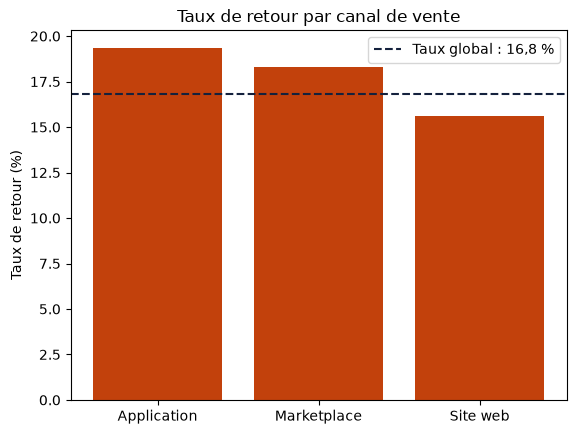

In [19]:
# Graphique : taux de retour par canal (on garde les 3 canaux principaux)
import matplotlib.pyplot as plt

df_canal = pd.read_sql_query(requete, connexion)
df_canal = df_canal[df_canal["canal"] != "Non renseigné"]   # seulement 8 ventes, on ne les affiche pas

plt.bar(df_canal["canal"], df_canal["taux_retour_pct"], color="#C2410C")
plt.axhline(16.8, color="#14213D", linestyle="--", label="Taux global : 16,8 %")   # moyenne de toutes les ventes valides
plt.ylabel("Taux de retour (%)")
plt.title("Taux de retour par canal de vente")
plt.legend()
plt.savefig("graphique_retours_par_canal.png", dpi=150, bbox_inches="tight")   # image pour la présentation
plt.show()


### 5.4 — Évolution mensuelle du CA

In [20]:
# CA par mois : SUBSTR garde les 7 premiers caractères de la date (AAAA-MM)
requete = """
SELECT SUBSTR(date_commande, 1, 7) AS mois, ROUND(SUM(montant), 2) AS ca, COUNT(*) AS nb_ventes
FROM ventes_valides
WHERE retour = 0
GROUP BY mois
ORDER BY mois;
"""
display(pd.read_sql_query(requete, connexion))

,mois,ca,nb_ventes
0,2025-01,9663.90,112
1,2025-02,8974.84,114
2,2025-03,12719.34,148
3,2025-04,8630.02,115
4,2025-05,10117.81,135
5,2025-06,11067.37,132
6,2025-07,11223.37,127
7,2025-08,9427.81,123
8,2025-09,8613.40,110
9,2025-10,9696.59,131


In [21]:
# Contrôles : brut - retours = CA ; somme des catégories = CA ; somme des mois = CA
requete = """
SELECT 'brut (avec retours)' AS controle, ROUND(SUM(montant), 2) AS valeur FROM ventes_valides
UNION ALL
SELECT 'retours remboursés', ROUND(SUM(montant), 2) FROM ventes_valides WHERE retour = 1
UNION ALL
SELECT 'CA total', ROUND(SUM(montant), 2) FROM ventes_valides WHERE retour = 0
UNION ALL
SELECT 'somme des catégories', ROUND(SUM(ca), 2) FROM (SELECT SUM(montant) AS ca FROM ventes_valides WHERE retour = 0 GROUP BY categorie)
UNION ALL
SELECT 'somme des mois', ROUND(SUM(ca), 2) FROM (SELECT SUM(montant) AS ca FROM ventes_valides WHERE retour = 0 GROUP BY SUBSTR(date_commande, 1, 7));
"""
display(pd.read_sql_query(requete, connexion))

,controle,valeur
0,brut (avec retours),238109.04
1,retours remboursés,43837.70
2,CA total,194271.34
3,somme des catégories,194271.34
4,somme des mois,194271.34


### 5.5 — Prix catalogue comparés aux prix concurrents

In [22]:
# Pour chaque produit ET chaque concurrent, on garde seulement le relevé le plus récent
# (on ignore les relevés sans prix). Résultat : 1 ligne par produit et par concurrent, donc pas de duplication
connexion.execute("DROP TABLE IF EXISTS prix_recents")
connexion.execute("""
CREATE TEMP TABLE prix_recents AS
SELECT c.id_produit, c.concurrent, c.date_releve, AVG(c.prix_concurrent) AS prix_concurrent   -- AVG sert seulement si 2 lignes identiques le même jour
FROM prix_concurrents c
WHERE c.prix_concurrent > 0
  AND c.date_releve = (
      SELECT MAX(c2.date_releve)
      FROM prix_concurrents c2
      WHERE c2.id_produit = c.id_produit
        AND c2.concurrent = c.concurrent
        AND c2.prix_concurrent > 0
  )
GROUP BY c.id_produit, c.concurrent, c.date_releve
""")
requete = """
SELECT COUNT(*) AS nb_lignes,
       COUNT(DISTINCT id_produit || concurrent) AS nb_couples_produit_concurrent,
       MIN(date_releve) AS date_min,
       MAX(date_releve) AS date_max
FROM prix_recents;
"""
display(pd.read_sql_query(requete, connexion))

,nb_lignes,nb_couples_produit_concurrent,date_min,date_max
0,128,128,2026-10-01,2026-10-01


In [23]:
# Écart moyen entre notre prix catalogue et celui de chaque concurrent (en %, positif = nous sommes plus chers)
requete = """
SELECT
  r.concurrent,
  COUNT(*) AS nb_produits,
  ROUND(AVG(100.0 * (p.prix_catalogue - r.prix_concurrent) / r.prix_concurrent), 2) AS ecart_moyen_pct,
  SUM(CASE WHEN p.prix_catalogue > r.prix_concurrent THEN 1 ELSE 0 END) AS nous_plus_chers,
  SUM(CASE WHEN p.prix_catalogue < r.prix_concurrent THEN 1 ELSE 0 END) AS nous_moins_chers
FROM prix_recents r
JOIN produits_propres p ON p.id_produit = r.id_produit
WHERE p.prix_catalogue IS NOT NULL
GROUP BY r.concurrent;
"""
display(pd.read_sql_query(requete, connexion))

,concurrent,nb_produits,ecart_moyen_pct,nous_plus_chers,nous_moins_chers
0,Concurrent A,63,0.31,31,32
1,Concurrent B,63,2.32,34,29


In [24]:
# Détail pour 10 produits : 1 ligne par produit, avec le prix de chaque concurrent côte à côte
requete = """
SELECT p.id_produit, p.categorie, p.prix_catalogue,
       a.prix_concurrent AS prix_A, b.prix_concurrent AS prix_B
FROM produits_propres p
LEFT JOIN prix_recents a ON a.id_produit = p.id_produit AND a.concurrent = 'Concurrent A'
LEFT JOIN prix_recents b ON b.id_produit = p.id_produit AND b.concurrent = 'Concurrent B'
ORDER BY p.id_produit
LIMIT 10;
"""
display(pd.read_sql_query(requete, connexion))

,id_produit,categorie,prix_catalogue,prix_A,prix_B
0,P0001,Casques,71.60,75.35,61.50
1,P0002,Textile,78.08,75.80,81.37
2,P0003,Gants,31.27,38.58,25.65
3,P0004,Eclairages,54.57,46.51,64.66
4,P0005,Antivols,36.35,34.21,34.03
5,P0006,Bidons,13.86,13.48,11.80
6,P0007,Chaussures,156.88,188.02,151.93
7,P0008,Sacs,77.18,92.13,66.43
8,P0009,Casques,86.36,79.57,96.27
9,P0010,Textile,77.29,65.40,86.54


**Contrôles et limites de l'étape 5** :
- **5.1** : CA total **194 271,34** pour **2941 ventes valides**, taux de retour **16,8 %** (494 sur 2941). Contrôle : 238 109,04 (brut) - 43 837,70 (retours) = 194 271,34. Limite : les 59 ventes exclues ne sont pas dans ce CA, il est donc probablement un peu sous-estimé.
- **5.2** : la somme des catégories est égale au CA total. Limite : les ventes sans produit connu n'ont pas de catégorie et sont exclues.
- **5.3** : taux le plus haut sur Application (19,35 %), le plus bas sur Site web (15,63 %). Limite : « Non renseigné » ne compte que 8 ventes, son taux (12,5 %) n'est pas fiable.
- **5.4** : la somme des 22 mois est égale au CA total. Limite : le CA est compté à la date de commande, pas à la date du retour.
- **5.5** : 128 lignes = 64 produits x 2 concurrents, tous au relevé du 2026-10-01. La comparaison porte sur 63 produits (P0038 n'a pas de prix catalogue). Limites : on compare le prix catalogue, pas le prix payé après remise ; on ne sait pas si l'article du concurrent est exactement le même.

## Étape 6 — Synthèse (à rédiger)

Présentez au moins trois observations chiffrées et deux limites de qualité ; distinguez ce qui est mesuré de ce qui est supposé.

## Réponse — Synthèse

### Observations chiffrées (mesurées)
1. **CA total de 194 271,34** (hors remboursements, après remises) sur **2941 ventes valides**. Les retours représentent 43 837,70, soit 18,4 % du montant brut (238 109,04).
2. **Taux de retour de 16,8 %**. Il est plus haut sur Application (19,35 %) et Marketplace (18,29 %) que sur Site web (15,63 %).
3. **Chaussures** est la première catégorie avec 51 224,04 (26,4 % du CA). **Bidons** est la dernière avec 8 521,12.
4. **Baisse en 2026** : de janvier à octobre, le CA passe d'environ 100 134 (2025) à 76 377 (2026), soit environ **-23,7 %**.
5. **Prix** : notre prix catalogue est en moyenne **+0,31 %** au-dessus du Concurrent A et **+2,32 %** au-dessus du Concurrent B. Les prix sont proches.

### Limites de qualité
1. **64 lignes exclues sur 3005** (5 doublons et 59 ventes invalides) : leur montant est inconnu, le CA est probablement un peu sous-estimé.
2. **Données manquantes** : 8 canaux vides (gardés), 1 prix catalogue vide (P0038), 6 prix concurrents vides et 3 prix <= 0 (dans d'anciens relevés).

### Mesuré ou supposé ?
- **Mesuré** : tous les chiffres ci-dessus, calculés en SQL sur les données nettoyées, avec des contrôles (somme des catégories = somme des mois = CA total).
- **Supposé** : (a) une vente retournée est remboursée en totalité ; (b) on exclut les lignes invalides au lieu de les corriger ; (c) la baisse de 2026 est une vraie baisse et non un manque de données (non vérifié) ; (d) les prix concurrents sont comparables à nos produits.